Dataset Shape: (768, 9)

First 3 rows:
    Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6      148             72             35        0  33.6   
1            1       85             66             29        0  26.6   
2            8      183             64              0        0  23.3   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  

Missing values (explicit NaNs):
 Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


<Figure size 1200x800 with 0 Axes>

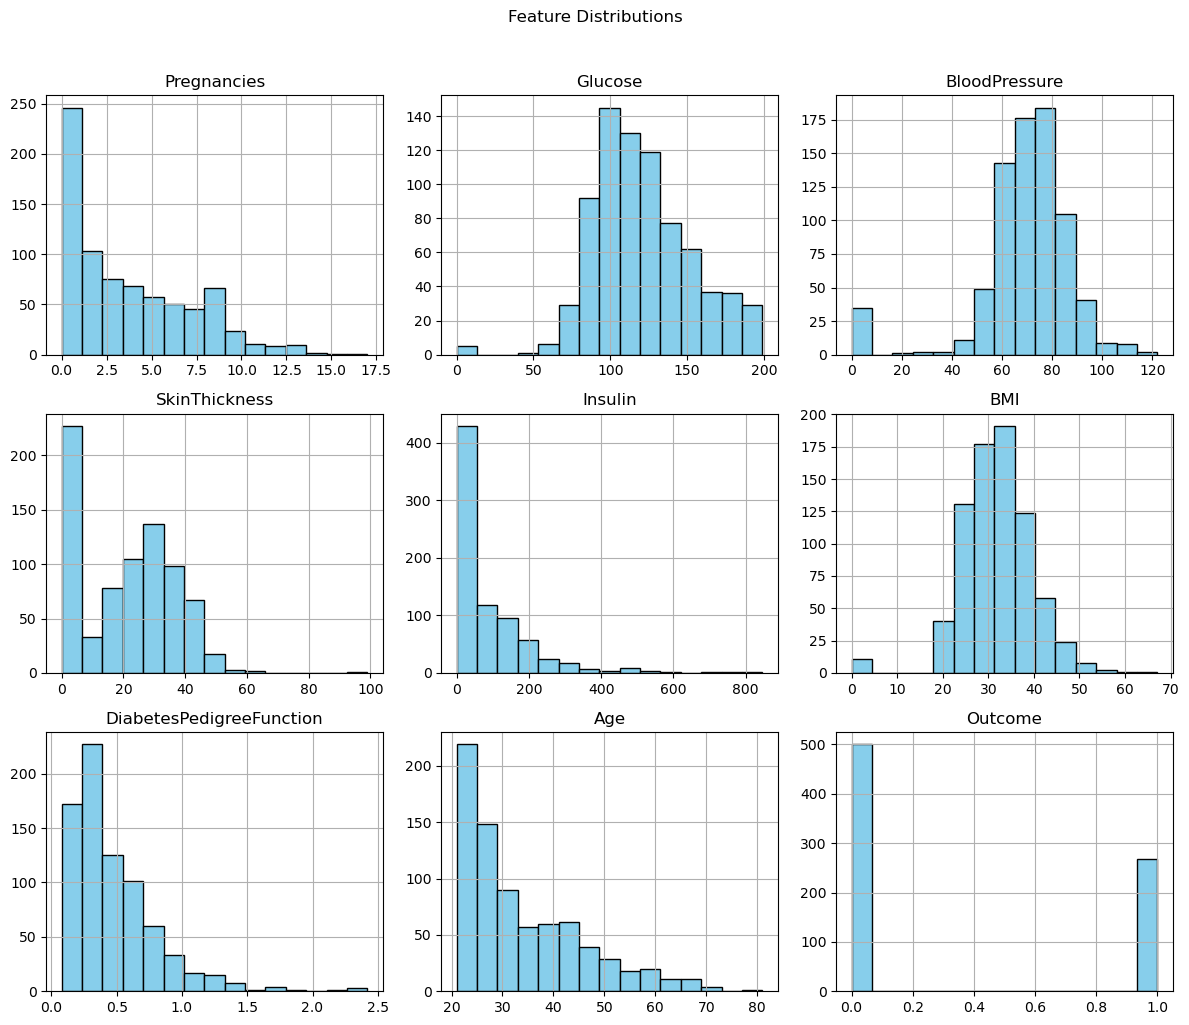

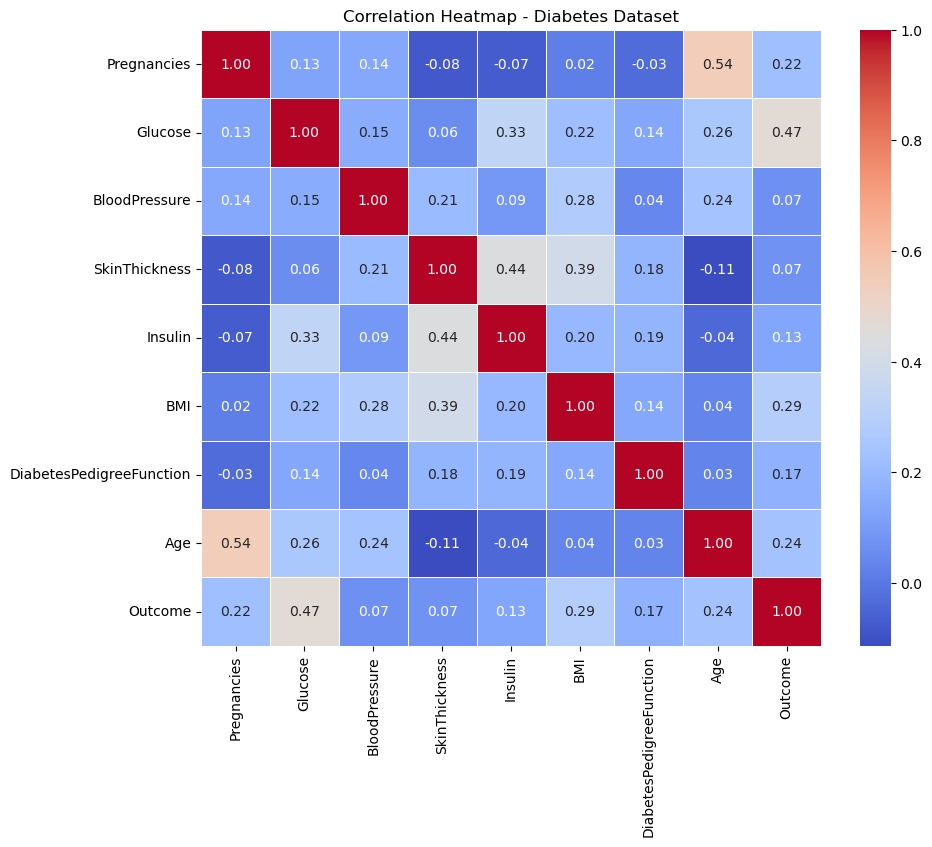

In [1]:
# LGBM & XGBM
# Step 1: Exploratory Data Analysis (EDA)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load Dataset
df = pd.read_csv('diabetes (1).csv')
print("Dataset Shape:", df.shape)
print("\nFirst 3 rows:\n", df.head(3))

# 2. Check for missing values (Note: In Pima Diabetes dataset, zeros often represent hidden missing values)
print("\nMissing values (explicit NaNs):\n", df.isnull().sum())

# 3. Explore feature distributions (Histograms & Box plots)
plt.figure(figsize=(12, 8))
df.hist(bins=15, figsize=(12, 10), color='skyblue', edgecolor='black')
plt.suptitle('Feature Distributions', y=1.02)
plt.tight_layout()
plt.show()

# 4. Correlation Matrix
plt.figure(figsize=(10, 8))
sns.heatmap(df.corr(), annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap - Diabetes Dataset')
plt.show()

In [5]:
#Step 2: Data Preprocessing
from sklearn.model_selection import train_test_split

# Replace biologically impossible 0s with NaN and impute with median
df_processed = df.copy()
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in cols_with_zeros:
    df_processed[col] = df_processed[col].replace(0, np.nan)
    df_processed[col] = df_processed[col].fillna(df_processed[col].median())

# Separate features and target
X = df_processed.drop(columns=['Outcome'])
y = df_processed['Outcome']

# Stratified 80-20 train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [6]:
#Step 3 & 4: Building Predictive Models (LightGBM & XGBoost)
from sklearn.model_selection import train_test_split
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report
import pandas as pd
import numpy as np

# 1. Load dataset & handle missing values
df = pd.read_csv('diabetes (1).csv')
df_processed = df.copy()
cols_with_zeros = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
for col in cols_with_zeros:
    df_processed[col] = df_processed[col].replace(0, np.nan)
    df_processed[col] = df_processed[col].fillna(df_processed[col].median())

# Separate features and target
X = df_processed.drop(columns=['Outcome'])
y = df_processed['Outcome']

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 2. Train Gradient Boosting Classifier
gb_model = GradientBoostingClassifier(random_state=42)
gb_model.fit(X_train, y_train)
gb_preds = gb_model.predict(X_test)

# 3. Evaluation Metrics
print("--- Gradient Boosting Model Performance ---")
print(f"Accuracy:  {accuracy_score(y_test, gb_preds):.4f}")
print(f"Precision: {precision_score(y_test, gb_preds):.4f}")
print(f"Recall:    {recall_score(y_test, gb_preds):.4f}")
print(f"F1-Score:  {f1_score(y_test, gb_preds):.4f}")
print("\nClassification Report:\n", classification_report(y_test, gb_preds))

--- Gradient Boosting Model Performance ---
Accuracy:  0.7597
Precision: 0.6889
Recall:    0.5741
F1-Score:  0.6263

Classification Report:
               precision    recall  f1-score   support

           0       0.79      0.86      0.82       100
           1       0.69      0.57      0.63        54

    accuracy                           0.76       154
   macro avg       0.74      0.72      0.72       154
weighted avg       0.75      0.76      0.75       154



In [7]:
# Task 5: Hyperparameter Tuning for XGBoost
import xgboost as xgb
from sklearn.model_selection import GridSearchCV

# Define hyperparameter grid
param_grid = {
    'max_depth': [3, 4, 5],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 200]
}

# Perform Grid Search
grid_search = GridSearchCV(
    xgb.XGBClassifier(random_state=42, eval_metric='logloss'), 
    param_grid, 
    cv=5, 
    scoring='f1'
)
grid_search.fit(X_train, y_train)

# Print Results
print("Best XGBoost Parameters:", grid_search.best_params_)
print(f"Best CV F1-Score: {grid_search.best_score_:.4f}")

Best XGBoost Parameters: {'learning_rate': 0.1, 'max_depth': 4, 'n_estimators': 100}
Best CV F1-Score: 0.6297
